In [2]:
import os, time, copy, math, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models

SEED = 42
def set_seed(seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)

# containers used for the final comparison tables
results = {}

PyTorch 2.14.1+cpu | torchvision 0.29.1+cpu | device: cpu


In [3]:
# ---- 1. Data loading (as in Listing 1) ----
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
print("train:", len(trainset), "test:", len(testset))

100.0%


train: 50000 test: 10000


In [4]:
# ---- 2. Network parameters ----
set_seed()
Din = 3 * 32 * 32      # flattened CIFAR-10 image
H   = 100              # hidden nodes (sigmoid)
K   = 10               # classes

g  = torch.Generator().manual_seed(SEED)
w1 = torch.randn(Din, H, generator=g) / math.sqrt(Din)
b1 = torch.zeros(H)
w2 = torch.randn(H, K, generator=g) / math.sqrt(H)
b2 = torch.zeros(K)

# Hyperparameters
epochs   = 10
lr       = 0.02
lr_decay = 0.9
reg      = 0.0         # L2 regularisation strength (try e.g. 1e-4 as an extra experiment)

# ---- helper functions (all manual – no autograd in the training path) ----
def forward(x):
    h = torch.sigmoid(x.mm(w1) + b1)     # hidden layer, sigmoid
    z = h.mm(w2) + b2                    # output logits
    return h, z

def cross_entropy(z, y_onehot):
    log_p = torch.log_softmax(z, dim=1)  # numerically stable softmax
    loss = -(y_onehot * log_p).sum() / z.shape[0]
    return loss, log_p.exp()

def manual_step(x, y_onehot):
    # returns loss and manual gradients
    N = x.shape[0]
    h, z = forward(x)
    ce, p = cross_entropy(z, y_onehot)
    loss = ce + reg * ((w1**2).sum() + (w2**2).sum())
    dz  = (p - y_onehot) / N
    dw2 = h.t().mm(dz) + 2 * reg * w2
    db2 = dz.sum(dim=0)
    dh  = dz.mm(w2.t())
    da1 = dh * h * (1 - h)               # sigmoid derivative
    dw1 = x.t().mm(da1) + 2 * reg * w1
    db1 = da1.sum(dim=0)
    return loss, (dw1, db1, dw2, db2), p

@torch.no_grad()
def accuracy(loader):
    correct = total = 0
    for inputs, labels in loader:
        x = inputs.view(inputs.shape[0], -1)
        _, z = forward(x)
        correct += (z.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return 100.0 * correct / total

In [5]:
inputs, labels = next(iter(trainloader))
x = inputs.view(inputs.shape[0], -1)
y = F.one_hot(labels, K).float()

with torch.no_grad():
    loss_m, grads_m, _ = manual_step(x, y)

# autograd reference (float64 for a precise comparison)
params = [t.clone().double().requires_grad_(True) for t in (w1, b1, w2, b2)]
a1 = torch.sigmoid(x.double().mm(params[0]) + params[1])
z  = a1.mm(params[2]) + params[3]
loss_a = F.cross_entropy(z, labels) + reg * ((params[0]**2).sum() + (params[2]**2).sum())
loss_a.backward()

print(f"loss manual = {loss_m.item():.6f} | autograd = {loss_a.item():.6f}")
for name, gm, p in zip(["dw1", "db1", "dw2", "db2"], grads_m, params):
    print(f"{name}: max |manual - autograd| = {(gm.double() - p.grad).abs().max().item():.2e}")

loss manual = 2.587881 | autograd = 2.587881
dw1: max |manual - autograd| = 2.97e-09
db1: max |manual - autograd| = 1.98e-09
dw2: max |manual - autograd| = 1.85e-08
db2: max |manual - autograd| = 1.20e-08


In [6]:
loss_history = []                       # per-iteration loss
epoch_log = {"loss": [], "train_acc": [], "test_acc": []}

t0 = time.time()
for t in range(epochs):
    running_loss, run_correct, run_total = 0.0, 0, 0
    for i, (inputs, labels) in enumerate(trainloader):
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)                       # (Ntr, Din)
        y_train_onehot = F.one_hot(labels, K).float()        # (Ntr, K)

        loss, (dw1, db1, dw2, db2), p = manual_step(x_train, y_train_onehot)
        loss_history.append(loss.item())
        running_loss += loss.item()
        run_correct += (p.argmax(1) == labels).sum().item()
        run_total += Ntr

        # parameter update (plain SGD)
        w1 -= lr * dw1;  b1 -= lr * db1
        w2 -= lr * dw2;  b2 -= lr * db2

    test_acc = accuracy(testloader)
    epoch_log["loss"].append(running_loss / len(trainloader))
    epoch_log["train_acc"].append(100.0 * run_correct / run_total)
    epoch_log["test_acc"].append(test_acc)
    print(f"Epoch {t+1:2d}/{epochs} | lr={lr:.5f} | loss={epoch_log['loss'][-1]:.4f} | "
          f"train acc (running)={epoch_log['train_acc'][-1]:.2f}% | test acc={test_acc:.2f}%")
    lr *= lr_decay                                           # learning-rate decay
print(f"Training time: {time.time()-t0:.1f}s")

Epoch  1/10 | lr=0.02000 | loss=1.9355 | train acc (running)=33.20% | test acc=36.50%
Epoch  2/10 | lr=0.01800 | loss=1.7924 | train acc (running)=38.14% | test acc=39.12%
Epoch  3/10 | lr=0.01620 | loss=1.7481 | train acc (running)=39.73% | test acc=39.76%
Epoch  4/10 | lr=0.01458 | loss=1.7208 | train acc (running)=40.65% | test acc=40.40%
Epoch  5/10 | lr=0.01312 | loss=1.7006 | train acc (running)=41.55% | test acc=41.09%
Epoch  6/10 | lr=0.01181 | loss=1.6852 | train acc (running)=41.97% | test acc=41.98%
Epoch  7/10 | lr=0.01063 | loss=1.6721 | train acc (running)=42.48% | test acc=41.66%
Epoch  8/10 | lr=0.00957 | loss=1.6608 | train acc (running)=42.90% | test acc=42.14%
Epoch  9/10 | lr=0.00861 | loss=1.6519 | train acc (running)=43.34% | test acc=42.59%
Epoch 10/10 | lr=0.00775 | loss=1.6439 | train acc (running)=43.49% | test acc=42.84%
Training time: 240.6s


Training accuracy: 43.71%
Test accuracy    : 42.84%


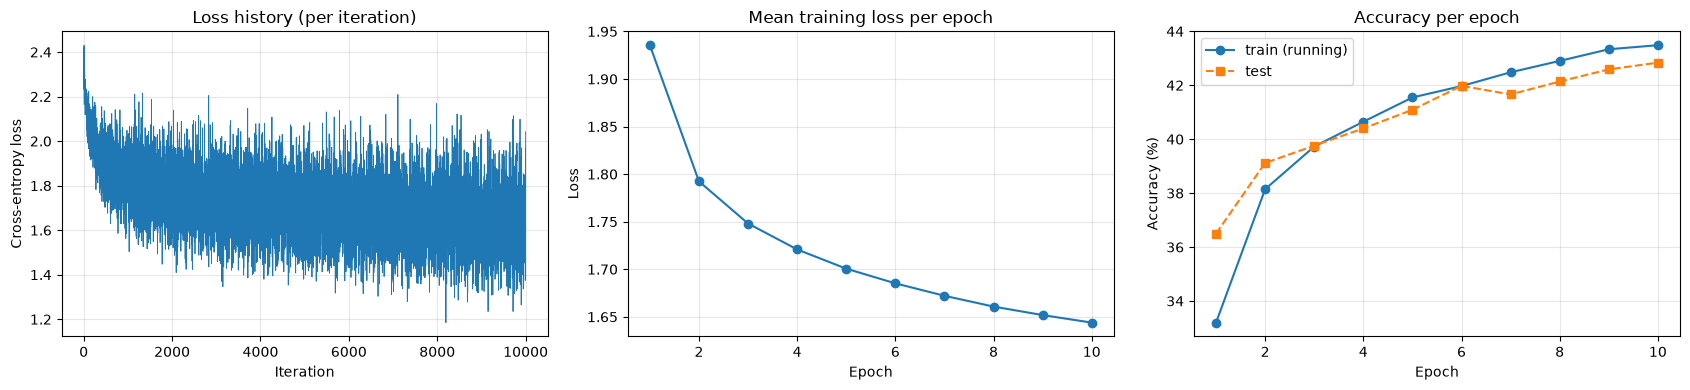

In [7]:
# ---- Final accuracies (full pass with the final weights) ----
train_acc_q1 = accuracy(trainloader)
test_acc_q1  = accuracy(testloader)
print(f"Training accuracy: {train_acc_q1:.2f}%")
print(f"Test accuracy    : {test_acc_q1:.2f}%")
results["Q1 – 3072-100(sigmoid)-10, CE, 10 ep"] = {"Train acc (%)": train_acc_q1, "Test acc (%)": test_acc_q1}

# ---- Plots ----
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(loss_history, lw=0.6); ax[0].set_title("Loss history (per iteration)")
ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].grid(alpha=.3)
ax[1].plot(range(1, epochs+1), epoch_log["loss"], "o-"); ax[1].set_title("Mean training loss per epoch")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].grid(alpha=.3)
ax[2].plot(range(1, epochs+1), epoch_log["train_acc"], "o-", label="train (running)")
ax[2].plot(range(1, epochs+1), epoch_log["test_acc"], "s--", label="test")
ax[2].set_title("Accuracy per epoch"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Accuracy (%)")
ax[2].legend(); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

# Question 2 – LeNet-5 vs. modern small CNN on MNIST


100.0%
100.0%
100.0%
100.0%


train: 60000 test: 10000


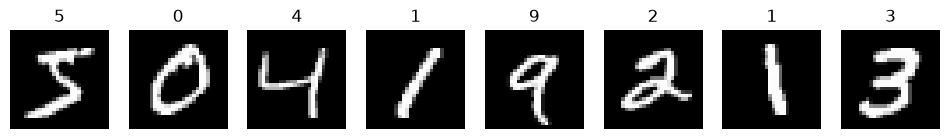

In [8]:
BATCH, EPOCHS, LR = 64, 10, 1e-3

mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
mn_train = datasets.MNIST("./data", train=True,  download=True, transform=mnist_tf)
mn_test  = datasets.MNIST("./data", train=False, download=True, transform=mnist_tf)
mn_train_loader = DataLoader(mn_train, batch_size=BATCH, shuffle=True,  num_workers=2)
mn_test_loader  = DataLoader(mn_test,  batch_size=1000, shuffle=False, num_workers=2)
mn_eval_train_loader = DataLoader(mn_train, batch_size=1000, shuffle=False, num_workers=2)
print("train:", len(mn_train), "test:", len(mn_test))

# quick look at the data
fig, ax = plt.subplots(1, 8, figsize=(12, 1.8))
for i, a in enumerate(ax):
    img, lab = mn_train[i]; a.imshow(img.squeeze(), cmap="gray"); a.set_title(lab); a.axis("off")
plt.show()